# TP2 · Clasificador de Fashion-MNIST con una MLP (configuración base)

MLP 784 → 128 → 64 → 10 con ReLU y Dropout 0,2, entrenada 20 épocas con mini-batches de 100. Se comparan SGD (lr = 0,01) y Adam (lr = 0,001) usando *validation*, se evalúa una sola vez en *test* y se analizan los errores (accuracy por clase y matriz de confusión).

*Ejecutada en Google Colab con GPU T4. En CPU los números cambian en la tercera o cuarta cifra.*

> **EN:** Baseline notebook (in Spanish): 784-128-64-10 MLP, SGD vs Adam chosen on validation, single test evaluation and error analysis. Run on a Colab T4 GPU.

In [5]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

### 1.2) Reproducibilidad y dispositivo

Fijamos semillas y elegimos automáticamente GPU si está disponible.

In [6]:
# 1.2) Reproducibilidad y dispositivo
SEED = 42

def set_seed(seed):
    """Fija todas las fuentes de azar que usamos: random de Python, NumPy y PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [7]:
# 2.1) Transformación: píxeles 0..255 -> [0,1] (ToTensor) -> [-1,1] (Normalize)
transform = transforms.Compose([
    transforms.ToTensor(),                  # (28,28) uint8 0..255  ->  (1,28,28) float 0..1
    transforms.Normalize((0.5,), (0.5,)),   # x_norm = (x - 0.5) / 0.5  ->  [-1, 1]
])

full_train = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# Precarga: aplicamos la transformación UNA vez y guardamos todo como tensores en memoria.
# El resultado es idéntico (la transformación no tiene azar) y el entrenamiento es ~10 veces más rápido,
# porque el DataLoader ya no convierte imagen por imagen en cada época.
from torch.utils.data import TensorDataset

def to_tensor_dataset(ds):
    xs, ys = zip(*DataLoader(ds, batch_size=10_000))
    return TensorDataset(torch.cat(xs), torch.cat(ys))

full_train = to_tensor_dataset(full_train)
test_set   = to_tensor_dataset(test_set)

# Comprobación de la observación de la guía: la media NO queda en 0
x_all = torch.stack([full_train[i][0] for i in range(5000)])   # 5000 imágenes alcanzan para estimar
print(f"min = {x_all.min():.2f}, max = {x_all.max():.2f}")
print(f"media = {x_all.mean():.3f}, desvío = {x_all.std():.3f}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.8MB/s]


min = -1.00, max = 1.00
media = -0.428, desvío = 0.709


### 2.2) *Train*, *validation* y *test*

Usaremos la misma metodología que en la guía del *autoencoder*:

- 50.000 imágenes para *train*;
- 10.000 imágenes para *validation*;
- 10.000 imágenes oficiales para *test*.

No visualizaremos nuevamente el *dataset* (ya lo hicimos en la guía de práctico del *Autoencoder*). Nos concentraremos directamente en la **tarea de clasificación**.

In [8]:
# 2.2) Train / validation / test
generator = torch.Generator().manual_seed(SEED)       # el corte 50.000 / 10.000 queda fijo
train_set, valid_set = random_split(full_train, [50_000, 10_000], generator=generator)

print("train:", len(train_set), " validation:", len(valid_set), " test:", len(test_set))

train: 50000  validation: 10000  test: 10000


### 2.3) Nombres de las clases

Fashion-MNIST codifica las categorías con **números enteros** de `0` a `9`.

El siguiente **diccionario** sólo se utilizará para traducir las **etiquetas numéricas** a **nombres legibles** cuando analicemos las predicciones.

In [9]:
# 2.3) Nombres de las clases
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}
print(class_names[6])

Shirt


## Ejercicio 3) Crear los `DataLoader`s

Como en el *autoencoder*, el entrenamiento se realiza **mini-batch por mini-batch**.

Usaremos *mini-batches* de 100 imágenes:

```text
images.shape = (B, 1, 28, 28)
labels.shape = (B,)
```

`train_loader` usa `shuffle=True`. *Validation* y *test* usan `shuffle=False`.

In [10]:
# 3) DataLoaders
BATCH_SIZE = 100

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

images, labels = next(iter(train_loader))
print("images.shape =", tuple(images.shape))   # (100, 1, 28, 28)
print("labels.shape =", tuple(labels.shape))   # (100,)
print("primeras etiquetas:", labels[:10].tolist())

images.shape = (100, 1, 28, 28)
labels.shape = (100,)
primeras etiquetas: [3, 6, 1, 2, 2, 6, 2, 3, 7, 0]


## Ejercicio 4) Comprender la tarea de clasificación

En un *autoencoder*:

$$
x\longrightarrow\hat{x}.
$$

En **clasificación supervisada**:

$$
x\longrightarrow y.
$$

Para una imagen, la red producirá un vector de 10 valores:

$$
\mathbb{z}
=
[z_0,z_1,\ldots,z_9]^T,
$$

donde cada $z_k$ es un *logit* para la clase $k$.

Los logits:

- son números reales;
- no son probabilidades;
- no tienen que estar entre 0 y 1;
- no tienen que sumar 1.

Conceptualmente, *softmax* transforma los *logits* en **probabilidades**:

$$
p_k
=
\frac{e^{z_k}}
{\sum_{j=0}^{9}e^{z_j}}.
$$

La clase predicha es la de mayor *logit*, equivalentemente la de **mayor probabilidad**:

$$
\hat{y}
=
\operatorname*{arg\,max}_k z_k.
$$

A diferencia del *autoencoder*, aquí **sí necesitamos las etiquetas** (por etiquetas nos referimos a los números enteros entre 0 y 9 que denotan cada clase, no nos referimos a los nombres de las clases) porque ellas indican cuál de las 10 clases es la correcta.

## Ejercicio 5) Definir la red de clasificación

Usaremos una MLP **completamente conectada**:

$$
784
\longrightarrow
128
\longrightarrow
64
\longrightarrow
10.
$$

Para un *mini-batch*:

$$
(B,1,28,28)
\longrightarrow
(B,784)
\longrightarrow
(B,128)
\longrightarrow
(B,64)
\longrightarrow
(B,10).
$$

La última capa produce 10 *logits*. No agregamos `Softmax` al modelo porque `CrossEntropyLoss` trabaja directamente con *logits*.

Incluiremos `Dropout(p=0.2)` después de las activaciones ocultas.

In [11]:
# 5) Red de clasificación: 784 -> 128 -> 64 -> 10
class FashionMLP(nn.Module):
    def __init__(self, dropout_p=0.2, h1=128, h2=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),               # (B,1,28,28) -> (B,784)
            nn.Linear(28 * 28, h1),     # (B,784) -> (B,128)
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(h1, h2),          # (B,128) -> (B,64)
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(h2, 10),          # (B,64) -> (B,10)  = logits (sin Softmax)
        )

    def forward(self, x):
        return self.net(x)

DROPOUT_P = 0.2

### 5.1) Comprobar dimensiones

Antes de entrenar, verificamos el *forward pass*.

Para $B$ imágenes y 10 clases esperamos:

$$
(B,1,28,28)
\longrightarrow
(B,10).
$$

In [12]:
# 5.1) Comprobar dimensiones
set_seed(SEED)
model = FashionMLP(DROPOUT_P).to(device)

with torch.no_grad():
    logits = model(images.to(device))
print("entrada:", tuple(images.shape), "-> salida:", tuple(logits.shape))

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("parámetros entrenables:", n_params)

entrada: (100, 1, 28, 28) -> salida: (100, 10)
parámetros entrenables: 109386


## Ejercicio 6) Función de pérdida

Para **clasificación multiclase** utilizaremos la función de pérdida denominada **Entropía Cruzada** ($L$) (`CrossEntropyLoss`).

Para un ejemplo cuya clase verdadera es $y$, conceptualmente:

$$
L
=
-\log(p_y),
$$

donde $p_y$ es la probabilidad asignada por *softmax* a la **clase correcta**.

PyTorch implementa de manera numéricamente estable la combinación:

```text
logits → log-softmax → negative log-likelihood
```

Por eso:

- la red debe devolver **logits**;
- no aplicamos `Softmax` antes de la pérdida;
- las etiquetas son enteros entre `0` y `9`, no vectores *one-hot*.

In [13]:
# 6) Función de pérdida
loss_fn = nn.CrossEntropyLoss()      # recibe logits (B,10) y etiquetas enteras (B,)

# Comprobación: CrossEntropyLoss = promedio de -log(softmax(z)[y])
manual = -torch.log_softmax(logits, dim=1)[torch.arange(len(labels)), labels.to(device)].mean()
print(f"CrossEntropyLoss = {loss_fn(logits, labels.to(device)).item():.4f}   manual = {manual.item():.4f}")
print(f"referencia ln(10) = {np.log(10):.4f}  (pérdida de una red que no sabe nada)")

CrossEntropyLoss = 2.3311   manual = 2.3311
referencia ln(10) = 2.3026  (pérdida de una red que no sabe nada)


## Ejercicio 7) Elegir el optimizador

Usaremos las mismas dos opciones que en la guía del *autoencoder*:

- SGD: `lr=0.01`;
- Adam: `lr=0.001`.

Comenzaremos con *Adam* y luego compararemos ambas configuraciones utilizando *validation*.

In [14]:
# 7) Optimizador
OPTIMIZER = "Adam"     # "SGD" o "Adam"
SGD_LR  = 0.01
ADAM_LR = 0.001
EPOCHS  = 20

## Ejercicio 8) Implementar una época de entrenamiento

El `DataLoader` entrega *mini-batches*:

```python
for images, labels in data_loader:
```

Para cada *mini-batch*:

1. activar modo **entrenamiento**;
2. mover imágenes y etiquetas al dispositivo;
3. borrar gradientes anteriores;
4. hacer *forward*;
5. calcular *Cross-Entropy Loss*;
6. hacer *backpropagation*;
7. actualizar parámetros.

Como en el *Autoencoder*, `optimizer.step()` es la instrucción que modifica los pesos.

In [15]:
# 8) Una época de entrenamiento
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()                                   # 1. modo entrenamiento (Dropout activo)
    for images, labels in data_loader:
        images = images.to(device)                  # 2. al dispositivo
        labels = labels.to(device)
        optimizer.zero_grad()                       # 3. borrar gradientes viejos
        logits = model(images)                      # 4. forward
        loss = loss_fn(logits, labels)              # 5. Cross-Entropy
        loss.backward()                             # 6. backpropagation (calcula gradientes)
        optimizer.step()                            # 7. actualiza los pesos

## Ejercicio 9) Implementar la evaluación

Durante evaluación:

- usamos `model.eval()`;
- desactivamos el cálculo de gradientes;
- no actualizamos parámetros;
- calculamos tanto pérdida (*loss*) como *accuracy*.

Para cada *mini-batch*:

```python
predictions = logits.argmax(dim=1)
```

selecciona la clase de mayor *logit* para cada imagen.

In [16]:
# 9) Evaluación: pérdida y accuracy, sin tocar los pesos
def evaluate(model, data_loader, loss_fn, device):
    model.eval()                                    # Dropout apagado
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():                           # no se arma el grafo de gradientes
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            b = labels.size(0)
            total_loss += loss.item() * b           # loss es promedio del batch: lo pasamos a suma
            predictions = logits.argmax(dim=1)      # clase de mayor logit
            correct += (predictions == labels).sum().item()
            n += b
    return total_loss / n, correct / n

## Ejercicio 10) Crear el modelo y el optimizador

Ahora creamos una instancia nueva del modelo y asociamos el optimizador seleccionado a sus parámetros.

In [17]:
# 10) Crear el modelo y el optimizador
set_seed(SEED)
model = FashionMLP(DROPOUT_P).to(device)

if OPTIMIZER == "SGD":
    optimizer = torch.optim.SGD(model.parameters(), lr=SGD_LR)
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LR)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### 10.1) Predicciones antes del entrenamiento

Antes del entrenamiento, los pesos son aleatorios. Por eso no esperamos predicciones útiles.

Usaremos *validation*, NO *test*, para observar algunas predicciones iniciales.

Esta sección cumple el mismo rol conceptual que las reconstrucciones antes de  entrenar el *autoencoder*: mostrar que la arquitectura por sí sola no sabe cómo clasificar imágenes correctamente todavía.

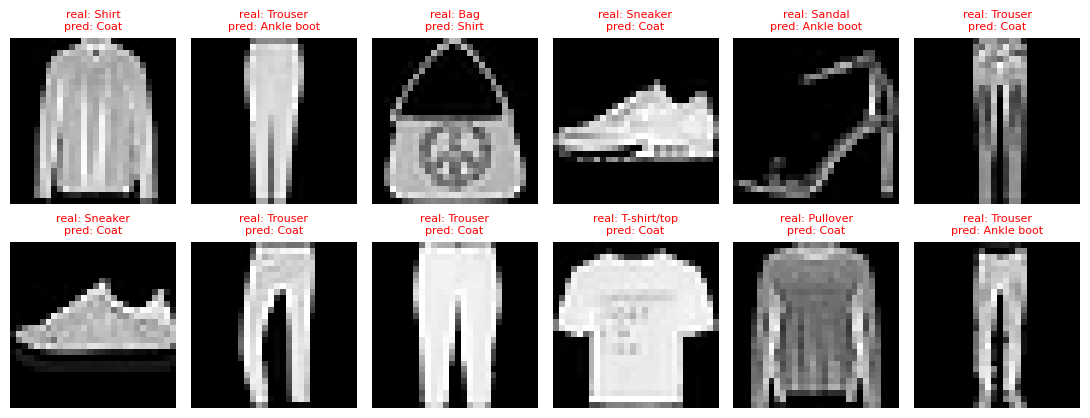

Antes de entrenar: valid loss = 2.3153, valid acc = 0.0954  (azar: ln10 = 2.3026, acc = 0.10)


In [18]:
# 10.1) Predicciones antes de entrenar (sobre validation, no test)
rng_state = torch.get_rng_state()     # guardamos el estado del azar: iter(DataLoader) lo consume
images_v, labels_v = next(iter(valid_loader))
model.eval()
with torch.no_grad():
    pred_v = model(images_v.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(11, 4.4))
for ax, img, y, p in zip(axes.flat, images_v, labels_v, pred_v):
    ax.imshow(0.5 * img.squeeze() + 0.5, cmap="gray")
    ax.set_title(f"real: {class_names[y.item()]}\npred: {class_names[p.item()]}", fontsize=8,
                 color="green" if p == y else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

loss0, acc0 = evaluate(model, valid_loader, loss_fn, device)
print(f"Antes de entrenar: valid loss = {loss0:.4f}, valid acc = {acc0:.4f}  (azar: ln10 = 2.3026, acc = 0.10)")
torch.set_rng_state(rng_state)        # así el entrenamiento del Ej. 11 coincide con run_experiment("Adam", ...)

## Ejercicio 11) Entrenar el modelo

En cada época:

```text
actualizar parámetros usando train
        ↓
evaluar train con los pesos finales
        ↓
evaluar validation con los mismos pesos
```

Así las métricas de *train* y *validation* corresponden exactamente al mismo estado del modelo.

Como en la guía del *autoencoder*, `train_one_epoch()` sólo actualiza pesos; las métricas se calculan después con `evaluate()`.

In [19]:
# 11) Entrenar
# Para evaluar train usamos un loader SIN shuffle: no consume el azar del train_loader.
train_eval_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False)

history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}

for epoch in range(1, EPOCHS + 1):
    train_one_epoch(model, train_loader, loss_fn, optimizer, device)        # aprende
    tr_loss, tr_acc = evaluate(model, train_eval_loader, loss_fn, device)   # mide train con los pesos finales
    va_loss, va_acc = evaluate(model, valid_loader, loss_fn, device)        # mide validation con los mismos pesos
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["valid_loss"].append(va_loss); history["valid_acc"].append(va_acc)
    print(f"época {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | valid loss {va_loss:.4f} acc {va_acc:.4f}")

época  1 | train loss 0.4396 acc 0.8401 | valid loss 0.4642 acc 0.8348
época  2 | train loss 0.3745 acc 0.8632 | valid loss 0.4044 acc 0.8541
época  3 | train loss 0.3437 acc 0.8750 | valid loss 0.3727 acc 0.8646
época  4 | train loss 0.3258 acc 0.8839 | valid loss 0.3555 acc 0.8729
época  5 | train loss 0.3105 acc 0.8839 | valid loss 0.3480 acc 0.8742
época  6 | train loss 0.3010 acc 0.8888 | valid loss 0.3404 acc 0.8749
época  7 | train loss 0.2863 acc 0.8921 | valid loss 0.3408 acc 0.8759
época  8 | train loss 0.2786 acc 0.8955 | valid loss 0.3356 acc 0.8796
época  9 | train loss 0.2634 acc 0.9012 | valid loss 0.3201 acc 0.8830
época 10 | train loss 0.2574 acc 0.9034 | valid loss 0.3184 acc 0.8845
época 11 | train loss 0.2584 acc 0.9047 | valid loss 0.3223 acc 0.8853
época 12 | train loss 0.2528 acc 0.9036 | valid loss 0.3143 acc 0.8837
época 13 | train loss 0.2390 acc 0.9117 | valid loss 0.3130 acc 0.8887
época 14 | train loss 0.2297 acc 0.9144 | valid loss 0.3168 acc 0.8885
época 

## Ejercicio 12) Graficar las métricas

En clasificación observaremos dos cantidades:

- `CrossEntropyLoss`;
- `accuracy`.

La **Pérdida** o **Error** (`CrossEntropyLoss` en este caso) es la función a partir de la cual se calculan los gradientes durante el proceso de entrenamiento de la red neuronal. La *accuracy* (exactitud) es una métrica interpretable de aciertos en el proceso de clasificación de las imágenes por parte de la red.

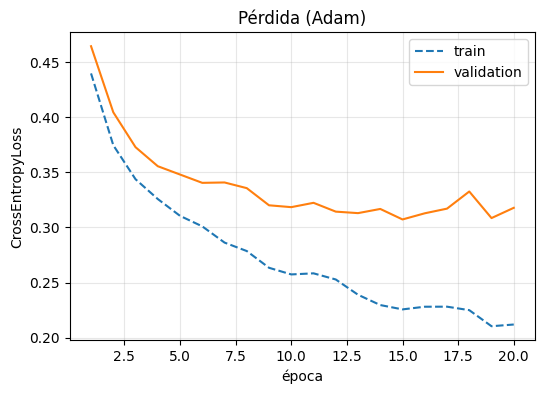

In [20]:
# 12) Pérdida en función de las épocas
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, history["train_loss"], "--", label="train")
plt.plot(epochs, history["valid_loss"], "-", label="validation")
plt.xlabel("época"); plt.ylabel("CrossEntropyLoss"); plt.title(f"Pérdida ({OPTIMIZER})")
plt.legend(); plt.grid(alpha=.3); plt.show()

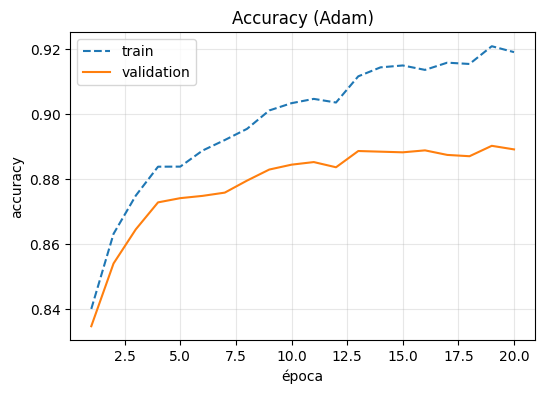

In [21]:
# 12) Accuracy en función de las épocas
plt.figure(figsize=(6, 4))
plt.plot(epochs, history["train_acc"], "--", label="train")
plt.plot(epochs, history["valid_acc"], "-", label="validation")
plt.xlabel("época"); plt.ylabel("accuracy"); plt.title(f"Accuracy ({OPTIMIZER})")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Ejercicio 13) Comparar *SGD* y *Adam* utilizando *validation*

Hasta este punto no necesitamos utilizar *test*.

En los Ejercicios 10, 11 y 12 entrenamos el modelo paso a paso. Para comparar configuraciones conviene **encapsular todo el experimento en una función**:

```text
fijar semillas → crear modelo → crear optimizador → entrenar → registrar métricas
```

Esto tiene dos ventajas:

- cada corrida devuelve su propio `history`, de modo que los resultados de una configuración **no sobrescriben** los de otra;
- como las semillas se fijan **dentro** de la función, cada corrida es **reproducible**: la inicialización de los pesos, el orden de los *mini-batches* y las máscaras de *Dropout* quedan determinados por `seed`, independientemente de qué celdas se hayan ejecutado antes.

Mantener constantes:
- arquitectura;
- dropout;
- batch size;
- número de épocas.

Comparar principalmente:

- `valid_loss` y `valid_acc` **de la última época**;
- velocidad de convergencia;
- estabilidad de las curvas.

**Elegir la configuración utilizando sólo *validation*.**

### 13.1) Función para ejecutar un experimento completo

`make_optimizer()` crea el optimizador a partir de su nombre y `run_experiment()` ejecuta un entrenamiento completo, igual al de los Ejercicios 10 y 11, y devuelve el modelo entrenado y su `history`.

Para evaluar *train* usamos un `DataLoader` **sin** `shuffle`: el orden no afecta a la evaluación y así no consumimos números aleatorios del generador que determina el orden de los *mini-batches* de entrenamiento.

In [22]:
# 13.1) Un experimento completo en una función
def make_optimizer(name, params, lr):
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr)
    if name == "Adam":
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(f"optimizador desconocido: {name}")


def run_experiment(opt_name, lr, seed=SEED, epochs=EPOCHS, dropout_p=DROPOUT_P, h1=128, h2=64, verbose=True):
    set_seed(seed)                                                    # todo el azar queda fijado por seed
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
    model = FashionMLP(dropout_p, h1, h2).to(device)
    optimizer = make_optimizer(opt_name, model.parameters(), lr)
    history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
    for epoch in range(1, epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer, device)
        tr_loss, tr_acc = evaluate(model, train_eval_loader, loss_fn, device)
        va_loss, va_acc = evaluate(model, valid_loader, loss_fn, device)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["valid_loss"].append(va_loss); history["valid_acc"].append(va_acc)
        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"  [{opt_name} lr={lr}] época {epoch:2d}: valid loss {va_loss:.4f}, valid acc {va_acc:.4f}")
    return model, history

### 13.2) Entrenar ambas configuraciones

Entrenamos SGD y Adam con la **misma semilla** y los mismos hiperparámetros, salvo el optimizador y su *learning rate*. Guardamos cada resultado en el diccionario `results`.

In [23]:
# 13.2) SGD y Adam con la misma semilla
configs = {"SGD": SGD_LR, "Adam": ADAM_LR}
results = {}
for name, lr in configs.items():
    print(name)
    results[name] = run_experiment(name, lr)

print()
print(f"{'optimizador':<12}{'lr':>8}{'valid loss':>12}{'valid acc':>11}")
for name, (m, h) in results.items():
    print(f"{name:<12}{configs[name]:>8}{h['valid_loss'][-1]:>12.4f}{h['valid_acc'][-1]:>11.4f}")

SGD
  [SGD lr=0.01] época  1: valid loss 0.8053, valid acc 0.7279
  [SGD lr=0.01] época  5: valid loss 0.5120, valid acc 0.8198
  [SGD lr=0.01] época 10: valid loss 0.4393, valid acc 0.8420
  [SGD lr=0.01] época 15: valid loss 0.4040, valid acc 0.8522
  [SGD lr=0.01] época 20: valid loss 0.3805, valid acc 0.8625
Adam
  [Adam lr=0.001] época  1: valid loss 0.4642, valid acc 0.8348
  [Adam lr=0.001] época  5: valid loss 0.3480, valid acc 0.8742
  [Adam lr=0.001] época 10: valid loss 0.3184, valid acc 0.8845
  [Adam lr=0.001] época 15: valid loss 0.3072, valid acc 0.8883
  [Adam lr=0.001] época 20: valid loss 0.3178, valid acc 0.8892

optimizador       lr  valid loss  valid acc
SGD             0.01      0.3805     0.8625
Adam           0.001      0.3178     0.8892


### 13.3) Comparar las curvas

Graficamos ambas configuraciones juntas: línea continua para *validation* y línea discontinua para *train*.

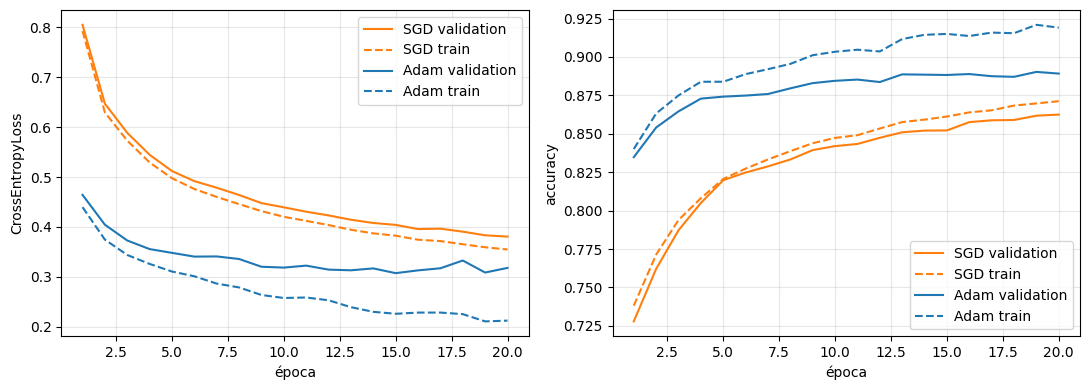

In [24]:
# 13.3) Curvas de ambas configuraciones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = {"SGD": "tab:orange", "Adam": "tab:blue"}
for name, (m, h) in results.items():
    ax1.plot(epochs, h["valid_loss"], "-",  color=colors[name], label=f"{name} validation")
    ax1.plot(epochs, h["train_loss"], "--", color=colors[name], label=f"{name} train")
    ax2.plot(epochs, h["valid_acc"],  "-",  color=colors[name], label=f"{name} validation")
    ax2.plot(epochs, h["train_acc"],  "--", color=colors[name], label=f"{name} train")
ax1.set_xlabel("época"); ax1.set_ylabel("CrossEntropyLoss"); ax1.grid(alpha=.3); ax1.legend()
ax2.set_xlabel("época"); ax2.set_ylabel("accuracy"); ax2.grid(alpha=.3); ax2.legend()
plt.tight_layout(); plt.show()

### 13.4) (Opcional) Variabilidad entre semillas

Una única corrida por configuración no permite saber si una diferencia en *validation* es **real** o es producto del azar (inicialización, orden de los *mini-batches*, *Dropout*).

Repitiendo cada configuración con varias semillas podemos estimar la media y el desvío estándar de las métricas, y preguntarnos: **¿es la diferencia entre SGD y Adam mayor que la variabilidad entre corridas?**

> Esta celda entrena $2\times3=6$ modelos, por lo que puede demorar varios minutos.

In [25]:
# 13.4) (Opcional) Variabilidad entre semillas: 2 optimizadores x 3 semillas
SEEDS = [0, 1, 2]
seed_results = {name: [] for name in configs}
for name, lr in configs.items():
    for s in SEEDS:
        _, h = run_experiment(name, lr, seed=s, verbose=False)
        seed_results[name].append((h["valid_loss"][-1], h["valid_acc"][-1]))
        print(f"{name} seed={s}: valid loss {h['valid_loss'][-1]:.4f}, valid acc {h['valid_acc'][-1]:.4f}")

print()
for name, vals in seed_results.items():
    v = np.array(vals)
    print(f"{name:<5} valid loss = {v[:,0].mean():.4f} ± {v[:,0].std(ddof=1):.4f}   "
          f"valid acc = {v[:,1].mean():.4f} ± {v[:,1].std(ddof=1):.4f}")

SGD seed=0: valid loss 0.3861, valid acc 0.8627
SGD seed=1: valid loss 0.3839, valid acc 0.8584
SGD seed=2: valid loss 0.3850, valid acc 0.8593
Adam seed=0: valid loss 0.3204, valid acc 0.8862
Adam seed=1: valid loss 0.3162, valid acc 0.8940
Adam seed=2: valid loss 0.3196, valid acc 0.8882

SGD   valid loss = 0.3850 ± 0.0011   valid acc = 0.8601 ± 0.0023
Adam  valid loss = 0.3187 ± 0.0022   valid acc = 0.8895 ± 0.0041


### 13.5) Fijar la configuración seleccionada

Elegir el optimizador **a partir de los resultados sobre *validation*** y recuperar el modelo entrenado y su `history` correspondientes.

A partir de aquí, `model` es el **modelo final**: el que se evaluará sobre *test* en los ejercicios siguientes. Sus curvas de entrenamiento son las que corresponde mostrar en el informe.

In [26]:
# 13.5) Configuración seleccionada (según validation, última época)
best = max(results, key=lambda name: results[name][1]["valid_acc"][-1])
print("Seleccionado:", best)

SELECTED = best
model, history = results[SELECTED]

Seleccionado: Adam


## Ejercicio 14) Evaluar la configuración seleccionada sobre *test*

La metodología es la misma que en el *autoencoder*:

$$
\text{train}
\longrightarrow
\text{aprendizaje de parámetros},
$$

$$
\text{validation}
\longrightarrow
\text{comparación de configuraciones},
$$

$$
\text{test}
\longrightarrow
\text{evaluación final}.
$$

Recién ahora medimos el modelo sobre las 10.000 imágenes oficiales de *test*.

In [27]:
# 14) Evaluación final sobre test (una sola vez)
test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(f"{SELECTED}: test loss = {test_loss:.4f}, test acc = {test_acc:.4f}")

Adam: test loss = 0.3333, test acc = 0.8838


## Ejercicio 15) Visualizar errores de clasificación sobre *test*

Ahora sí podemos observar imágenes concretas del conjunto de *test* porque la configuración ya fue seleccionada.

Las imágenes **bien** clasificadas aportan poca información. Mostraremos en cambio imágenes **mal clasificadas**: observarlas ayuda a entender qué tipo de errores comete la red y si resultan razonables desde el punto de vista visual.

Como las imágenes están normalizadas a `[-1,1]`, para visualizarlas recuperamos el intervalo `[0,1]` invirtiendo la transformación: $x = 0.5\,x_{\mathrm{norm}} + 0.5$.

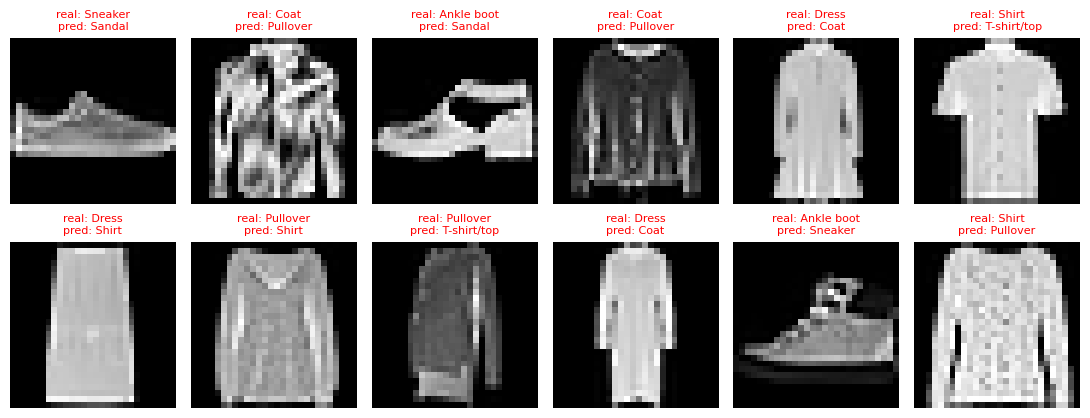

errores totales en test: 1162 de 10000


In [28]:
# 15) Errores de clasificación sobre test
model.eval()
all_preds, all_labels, wrong = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds = model(images.to(device)).argmax(dim=1).cpu()
        all_preds.append(preds); all_labels.append(labels)
        for img, y, p in zip(images, labels, preds):
            if p != y and len(wrong) < 12:
                wrong.append((img, y.item(), p.item()))
all_preds = torch.cat(all_preds); all_labels = torch.cat(all_labels)

fig, axes = plt.subplots(2, 6, figsize=(11, 4.4))
for ax, (img, y, p) in zip(axes.flat, wrong):
    ax.imshow(0.5 * img.squeeze() + 0.5, cmap="gray")       # deshacer la normalización
    ax.set_title(f"real: {class_names[y]}\npred: {class_names[p]}", fontsize=8, color="red")
    ax.axis("off")
plt.tight_layout(); plt.show()
print("errores totales en test:", (all_preds != all_labels).sum().item(), "de", len(all_labels))

## Ejercicio 16) *Accuracy* por clase

La *accuracy* global puede ocultar diferencias entre categorías.

Para cada clase $k$ calculamos:

$$
\mathrm{accuracy}_k
=
\frac{\mathrm{correctos\ de\ la\ clase}\ k}
{\mathrm{ejemplos\ de\ la\ clase}\ k}.
$$

Esta evaluación se hace sobre el conjunto *test* **después de haber seleccionado el modelo**.

In [29]:
# 16) Accuracy por clase (test)
for k in range(10):
    mask = all_labels == k
    acc_k = (all_preds[mask] == k).float().mean().item()
    print(f"{k} {class_names[k]:<12} {acc_k:.3f}")

0 T-shirt/top  0.845
1 Trouser      0.970
2 Pullover     0.805
3 Dress        0.916
4 Coat         0.857
5 Sandal       0.955
6 Shirt        0.623
7 Sneaker      0.966
8 Bag          0.969
9 Ankle boot   0.932


### 16.1) Matriz de confusión normalizada

La *accuracy* por clase resume cuántos ejemplos de cada clase fueron clasificados correctamente, pero no muestra **con qué otras clases se confunden los errores**.

Para obtener esa información utilizaremos una **matriz de confusión normalizada**.

Definimos una matriz $C$ de tamaño $10\times10$ donde:

- cada **fila** corresponde a la **clase verdadera**;
- cada **columna** corresponde a la **clase predicha**;
- $C_{ij}$ cuenta cuántos ejemplos cuya clase verdadera es $i$ fueron clasificados como clase $j$.

Por ejemplo:

$$
C_{6,0}
$$

indica cuántas imágenes cuya clase verdadera es `Shirt` fueron clasificadas como `T-shirt/top`.

La diagonal

$$
C_{00},C_{11},\ldots,C_{99}
$$

contiene las clasificaciones correctas.

Para facilitar la comparación entre clases, normalizaremos cada fila:

$$
C^{(\mathrm{norm})}_{ij}
=
\frac{C_{ij}}
{\sum_{k=0}^{9}C_{ik}}.
$$

Entonces cada fila suma aproximadamente 1:

$$
\sum_{j=0}^{9} C^{(\mathrm{norm})}_{ij}=1.
$$

De esta forma, cada elemento puede interpretarse como una **proporción de ejemplos de la clase verdadera $i$ que fueron asignados a la clase $j$**.

En una matriz de confusión normalizada ideal:

- la diagonal tendría valores cercanos a 1;
- los valores fuera de la diagonal serían cercanos a 0.

> **Importante:** esta matriz se calcula sobre `test_loader` porque ya hemos seleccionado la configuración final del modelo usando *validation*.

> **Clase 12/11:** la matriz se arma con las **clases predichas** (`argmax` de los logits), no con probabilidades. Las probabilidades sólo intervienen en la pérdida, y eso lo hace `CrossEntropyLoss` por dentro.

In [30]:
# 16.1) Matriz de confusión: filas = clase verdadera, columnas = clase predicha
C = torch.zeros(10, 10, dtype=torch.long)
for y, p in zip(all_labels, all_preds):
    C[y, p] += 1

C_norm = C.float() / C.sum(dim=1, keepdim=True)     # cada fila suma 1
print("sumas por fila:", C_norm.sum(dim=1).numpy().round(3))

# Las confusiones más grandes (fuera de la diagonal)
off = C_norm.clone(); off.fill_diagonal_(0)
top = torch.topk(off.flatten(), 6)
for val, idx in zip(top.values, top.indices):
    i, j = divmod(idx.item(), 10)
    print(f"{class_names[i]:>12} -> {class_names[j]:<12} {val:.3f}")

sumas por fila: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
       Shirt -> T-shirt/top  0.129
       Shirt -> Coat         0.112
    Pullover -> Coat         0.105
 T-shirt/top -> Shirt        0.090
       Shirt -> Pullover     0.080
        Coat -> Pullover     0.077


#### Visualización de la matriz

Representaremos la matriz normalizada como una imagen en escala de colores.

Para interpretar el gráfico:

- el eje vertical indica la **clase verdadera**;
- el eje horizontal indica la **clase predicha**;
- los valores de la diagonal representan **clasificaciones correctas**;
- los valores fuera de la diagonal muestran los pares de clases que la red confunde.

Como la matriz está normalizada por filas, los valores se encuentran entre 0 y 1.

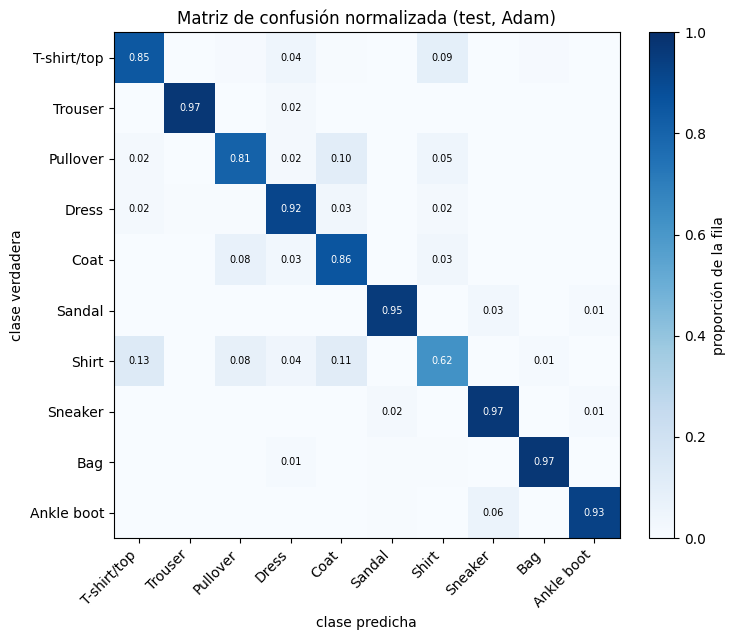

In [31]:
# Visualización de la matriz normalizada
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(C_norm.numpy(), cmap="Blues", vmin=0, vmax=1)
names = [class_names[k] for k in range(10)]
ax.set_xticks(range(10)); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(names)
ax.set_xlabel("clase predicha"); ax.set_ylabel("clase verdadera")
for i in range(10):
    for j in range(10):
        v = C_norm[i, j].item()
        if v >= 0.01:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, label="proporción de la fila")
ax.set_title(f"Matriz de confusión normalizada (test, {SELECTED})")
plt.tight_layout(); plt.show()

#### Cómo interpretar el resultado

La diagonal de la matriz permite observar, clase por clase, qué proporción fue clasificada correctamente.

Por ejemplo, si para una determinada clase aparece:

$$
C^{(\mathrm{norm})}_{ii}=0.91,
$$

significa que aproximadamente el 91 % de los ejemplos de esa clase fueron clasificados correctamente.

Un valor fuera de la diagonal, por ejemplo:

$$
C^{(\mathrm{norm})}_{ij}=0.08,
$$

significa que aproximadamente el 8 % de los ejemplos cuya clase verdadera es $i$ fueron confundidos con la clase $j$.

La matriz de confusión complementa la *accuracy* global porque permite responder preguntas como:

- ¿qué clases son fáciles de reconocer?
- ¿qué clases son más difíciles?
- ¿qué pares de clases se confunden frecuentemente?
- ¿los errores tienen una estructura visual razonable?

En Fashion-MNIST es especialmente interesante observar posibles confusiones entre categorías visualmente semejantes, por ejemplo prendas de la parte superior del cuerpo.

## Ejercicio 17) Preguntas conceptuales

1. ¿Por qué en clasificación necesitamos las etiquetas y en el *autoencoder* no?
2. ¿Qué representa cada uno de los 10 *logits*?
3. ¿Por qué los *logits* no son probabilidades?
4. ¿Qué hace conceptualmente *softmax*?
5. ¿Por qué no agregamos `Softmax` al modelo cuando usamos `CrossEntropyLoss`?
6. ¿Qué recibe `CrossEntropyLoss` como predicción y como *target*?
7. ¿Qué hace `optimizer.zero_grad()`?
8. ¿Qué hace `loss.backward()`?
9. ¿Qué hace `optimizer.step()`?
10. ¿Por qué el bucle `for images, labels in data_loader` recorre *mini-batches*?
11. ¿Por qué evaluamos *train* nuevamente al terminar cada época?
12. ¿Qué diferencia existe entre `model.train()` y `model.eval()`?
13. ¿Qué ocurre con *Dropout* durante evaluación?
14. ¿Qué diferencia conceptual existe entre *loss* y *accuracy*?
15. ¿Por qué *validation* sirve para elegir una configuración y *test* no debería utilizarse para ello?
16. ¿Por qué *SGD* y *Adam* utilizan *learning rates* iniciales diferentes?

### Respuestas (Ejercicio 17)

1. **Etiquetas:** en clasificación el objetivo es la clase $y$, que no está en la imagen; hay que dársela a la red. En el *autoencoder* el objetivo era la propia entrada $x$.
2. **Cada logit** $z_k$ es un puntaje real de "cuánto se parece la imagen a la clase $k$": cuanto mayor, más probable según la red.
3. **No son probabilidades** porque pueden ser negativos, mayores que 1 y no suman 1. Sólo importan sus diferencias.
4. ***Softmax*** exponencia (todo queda positivo) y divide por la suma (todo suma 1): convierte puntajes en una distribución de probabilidad que respeta el orden de los logits.
5. **Sin `Softmax` en el modelo** porque `CrossEntropyLoss` ya aplica *log-softmax* adentro. Si la agregamos, se aplicaría dos veces: la pérdida sigue siendo calculable pero queda mal escalada y los gradientes se achican.
6. **`CrossEntropyLoss` recibe** logits de forma `(B,10)` (predicción) y etiquetas enteras `(B,)` con valores 0..9 (*target*), no vectores *one-hot*.
7. **`optimizer.zero_grad()`** pone en cero los `.grad` de los parámetros; PyTorch **acumula** gradientes, así que sin esto se sumarían los de batches anteriores.
8. **`loss.backward()`** recorre el grafo hacia atrás y deja en cada parámetro su $\partial L/\partial w$. No cambia los pesos.
9. **`optimizer.step()`** usa esos gradientes para actualizar los pesos (SGD: $w \leftarrow w-\eta\,\nabla L$; Adam: paso con momentos).
10. **Mini-batches:** el `DataLoader` parte las 50.000 imágenes en 500 lotes de 100; cada vuelta del `for` entrega un lote y hace una actualización.
11. **Re-evaluar train** al final de la época da la métrica de train con los **mismos pesos** que validation (y con Dropout apagado). Promediar durante la época mezclaría modelos distintos.
12. **`model.train()` / `model.eval()`** activan o desactivan las capas que se comportan distinto al entrenar (aquí, Dropout).
13. **Dropout en evaluación** no apaga nada: se usa la red completa. (Durante el entrenamiento, PyTorch multiplica por $1/(1-p)$ las neuronas que sobreviven, para que la escala sea la misma.)
14. **Loss vs accuracy:** la *loss* es continua y mide también la confianza (se usa para los gradientes); la *accuracy* sólo cuenta aciertos del argmax (interpretable, pero no derivable).
15. **Validation vs test:** si elegimos con test, test deja de ser "datos nunca usados" y su número queda optimista. Validation se "gasta" eligiendo; test se reserva para el número final.
16. **Learning rates distintos:** SGD da pasos proporcionales al gradiente, que es chico, y necesita $\eta$ más grande; Adam normaliza cada componente por su tamaño típico, así que el paso es de orden $\eta$ y con $10^{-3}$ alcanza.


## Ejercicio 18) Experimentos sugeridos

Modificar una sola variable por vez ayuda a interpretar el efecto de cada **hiperparámetro**.

### 18.1) Learning rate con SGD

Probar:

```python
SGD_LR = 0.001
SGD_LR = 0.01
SGD_LR = 0.05
```

### 18.2) Dropout

Probar:

```python
DROPOUT_P = 0.0
DROPOUT_P = 0.2
DROPOUT_P = 0.5
```

### 18.3) Número de épocas

Probar:

```python
EPOCHS = 5
EPOCHS = 10
EPOCHS = 20
```

### 18.4) Optimizador

Comparar *SGD* y *Adam* con sus *learning rates* base.

### 18.5) Capacidad de aprendizaje del modelo

Cambiar, por ejemplo, la primera capa oculta:

```text
64 → 64 → 10
128 → 64 → 10
256 → 64 → 10
```

**Regla metodológica:** comparar configuraciones usando *validation* y reservar *test* para la configuración final.

### 18.1) Learning rate con SGD

In [32]:
sgd_lr_results = {}
for lr in [0.001, 0.01, 0.05]:
    _, h = run_experiment("SGD", lr, verbose=False)
    sgd_lr_results[lr] = h
    print(f"SGD lr={lr:<6}: valid loss {h['valid_loss'][-1]:.4f}, valid acc {h['valid_acc'][-1]:.4f}")

SGD lr=0.001 : valid loss 0.6433, valid acc 0.7644
SGD lr=0.01  : valid loss 0.3805, valid acc 0.8625
SGD lr=0.05  : valid loss 0.3141, valid acc 0.8857


### 18.2) Dropout (con el optimizador seleccionado)

> **Clase 12/11:** el dropout es lo primero que conviene mover si hay sobreajuste, pero nunca más allá de 0,4–0,5. Con 0,5 ya se ve subajuste (abajo).

In [33]:
sel_lr = configs[SELECTED]
dropout_results = {}
for p in [0.0, 0.2, 0.5]:
    _, h = run_experiment(SELECTED, sel_lr, dropout_p=p, verbose=False)
    dropout_results[p] = h
    gap = h["valid_loss"][-1] - h["train_loss"][-1]
    print(f"dropout={p}: train loss {h['train_loss'][-1]:.4f}, valid loss {h['valid_loss'][-1]:.4f}, "
          f"gap {gap:.4f}, valid acc {h['valid_acc'][-1]:.4f}")

dropout=0.0: train loss 0.1554, valid loss 0.3297, gap 0.1742, valid acc 0.8949
dropout=0.2: train loss 0.2120, valid loss 0.3178, gap 0.1058, valid acc 0.8892
dropout=0.5: train loss 0.2927, valid loss 0.3511, gap 0.0584, valid acc 0.8754


### 18.3) Número de épocas

Con la semilla fijada dentro de `run_experiment`, entrenar 5 o 10 épocas da **exactamente** los mismos números que las primeras 5 o 10 épocas de la corrida de 20. Basta con leer el `history`:

In [34]:
for name, (m, h) in results.items():
    for E in [5, 10, 20]:
        print(f"{name:<5} {E:2d} épocas: valid loss {h['valid_loss'][E-1]:.4f}, valid acc {h['valid_acc'][E-1]:.4f}")
    i = int(np.argmin(h["valid_loss"]))
    print(f"      mínimo de valid loss en la época {i+1}: {h['valid_loss'][i]:.4f}")

SGD    5 épocas: valid loss 0.5120, valid acc 0.8198
SGD   10 épocas: valid loss 0.4393, valid acc 0.8420
SGD   20 épocas: valid loss 0.3805, valid acc 0.8625
      mínimo de valid loss en la época 20: 0.3805
Adam   5 épocas: valid loss 0.3480, valid acc 0.8742
Adam  10 épocas: valid loss 0.3184, valid acc 0.8845
Adam  20 épocas: valid loss 0.3178, valid acc 0.8892
      mínimo de valid loss en la época 15: 0.3072


### 18.3 bis) ¿Había convergido SGD? (60 épocas)

In [35]:
_, h_sgd60 = run_experiment("SGD", SGD_LR, epochs=60, verbose=False)
for E in [20, 40, 60]:
    print(f"SGD {E} épocas: valid loss {h_sgd60['valid_loss'][E-1]:.4f}, valid acc {h_sgd60['valid_acc'][E-1]:.4f}")

SGD 20 épocas: valid loss 0.3805, valid acc 0.8625
SGD 40 épocas: valid loss 0.3365, valid acc 0.8782
SGD 60 épocas: valid loss 0.3164, valid acc 0.8863


### 18.5) Capacidad del modelo (primera capa oculta)

> **Clase 12/11:** 128/64 es una arquitectura de ejemplo. Se puede cambiar el número de neuronas o agregar capas (con al menos dos ocultas); acá se cambia sólo la primera capa, para mover un hiperparámetro por vez.

In [36]:
capacity_results = {}
for h1 in [64, 128, 256]:
    _, h = run_experiment(SELECTED, sel_lr, h1=h1, verbose=False)
    capacity_results[h1] = h
    n = sum(p.numel() for p in FashionMLP(DROPOUT_P, h1).parameters())
    print(f"{h1:>3} -> 64 -> 10 ({n:>6} parámetros): valid loss {h['valid_loss'][-1]:.4f}, valid acc {h['valid_acc'][-1]:.4f}")

 64 -> 64 -> 10 ( 55050 parámetros): valid loss 0.3298, valid acc 0.8823
128 -> 64 -> 10 (109386 parámetros): valid loss 0.3178, valid acc 0.8892
256 -> 64 -> 10 (218058 parámetros): valid loss 0.3189, valid acc 0.8915


### 18.6) Tabla de pruebas para el informe

> **Clase 12/11:** no hace falta poner las figuras de todas las pruebas: se resumen en **una tabla** (qué se cambió, pérdida de train y validation, exactitud) y sólo el modelo elegido se desarrolla con curvas y matriz. Esta celda arma esa tabla con los experimentos de arriba.

In [37]:
# 18.6) Tabla de pruebas para el informe: cada fila cambia UN hiperparámetro respecto de la base
base = results[SELECTED][1]
rows = [("Base (elegida)", "—", base),
        ("Otro optimizador", f"{SELECTED} → {[n for n in results if n != SELECTED][0]}", results[[n for n in results if n != SELECTED][0]][1]),
        ("Sin dropout", "p = 0,2 → 0", dropout_results[0.0]),
        ("Dropout 0,5", "p = 0,2 → 0,5", dropout_results[0.5]),
        ("Capa 1 más chica", "128 → 64", capacity_results[64]),
        ("Capa 1 más grande", "128 → 256", capacity_results[256])]
print(f"{'configuración':<18} {'qué cambia':<16} {'loss train':>10} {'loss valid':>10} {'brecha':>7} {'acc valid':>9}")
for name, change, h in rows:
    tl, vl, va = h["train_loss"][-1], h["valid_loss"][-1], h["valid_acc"][-1]
    print(f"{name:<18} {change:<16} {tl:>10.3f} {vl:>10.3f} {vl - tl:>7.3f} {100 * va:>8.1f}%")

configuración      qué cambia       loss train loss valid  brecha acc valid
Base (elegida)     —                     0.212      0.318   0.106     88.9%
Otro optimizador   Adam → SGD            0.355      0.381   0.026     86.2%
Sin dropout        p = 0,2 → 0           0.155      0.330   0.174     89.5%
Dropout 0,5        p = 0,2 → 0,5         0.293      0.351   0.058     87.5%
Capa 1 más chica   128 → 64              0.236      0.330   0.094     88.2%
Capa 1 más grande  128 → 256             0.189      0.319   0.130     89.1%
